# CacheGuard: Synthetic-Data Pipeline Demo

> **WARNING: SYNTHETIC DATA ONLY.**
> Every number in this notebook is randomly generated by code. It is **not** a real CPU measurement.
> The scores below only prove that the code runs. They do **not** show that CacheGuard detects a real covert channel.
> Real results must wait for a documented, valid experiment.

**What this notebook does**
1. Creates a small fake dataset (normal vs suspicious runs).
2. Splits it by run, so samples from one run never appear in both train and test.
3. Trains three baseline models.
4. Shows accuracy, precision, recall, F1-score and a confusion matrix.
5. Saves a demo model (clearly named synthetic).

Label meaning: **0 = normal**, **1 = suspicious**.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib

from sklearn.model_selection import GroupShuffleSplit
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix, ConfusionMatrixDisplay)

rng = np.random.default_rng(42)
print("Packages loaded")

Packages loaded


## 1. Create the synthetic dataset

Each **run** has many samples. We make 20 runs per label. Suspicious runs get a higher cache-miss rate on average.
The two classes overlap on purpose, so the data is not perfectly separable.

In [2]:
rows = []
run_id = 0
for label in [0, 1]:                      # 0 = normal, 1 = suspicious
    for _ in range(20):                   # 20 runs per label
        run_id += 1
        miss_rate_mean = 0.06 if label == 0 else 0.10
        for _ in range(30):               # 30 samples per run
            refs = rng.normal(1_200_000, 150_000)
            miss_rate = max(0.005, rng.normal(miss_rate_mean, 0.03))
            instr = rng.normal(9_500_000, 1_000_000)
            cycles = rng.normal(6_100_000, 700_000)
            rows.append({
                "run_id": run_id,
                "cache_references": refs,
                "cache_misses": refs * miss_rate,
                "instructions": instr,
                "cpu_cycles": cycles,
                "label": label,
            })

df = pd.DataFrame(rows)
df.to_csv("../data/processed/synthetic_dataset.csv", index=False)
print(df.shape)
df.head()

(1200, 6)


,run_id,cache_references,cache_misses,instructions,cpu_cycles,label
0,1,1.245708e+06,35876.971754,1.025045e+07,6.758395e+06,0
1,1,9.073447e+05,18994.912234,9.627840e+06,5.878630e+06,0
2,1,1.197480e+06,41203.702754,1.037940e+07,6.644454e+06,0
3,1,1.209905e+06,113509.906083,9.967509e+06,5.498495e+06,0
4,1,1.255313e+06,39207.834228,1.037845e+07,6.065052e+06,0


## 2. Inspect the data

In [3]:
print(df["label"].value_counts().rename({0: "normal", 1: "suspicious"}))
print()
print("Missing values:", int(df.isna().sum().sum()))
df.groupby("label")[["cache_references", "cache_misses", "instructions", "cpu_cycles"]].mean().round(0)

label
normal        600
suspicious    600
Name: count, dtype: int64

Missing values: 0


,cache_references,cache_misses,instructions,cpu_cycles
label,,,,
0,1195520.0,71559.0,9439604.0,6064912.0
1,1204569.0,121166.0,9471847.0,6111986.0


## 3. Split by run (prevents data leakage)

Samples from the same run are very similar. If some go into training and others into testing, the score looks better than it should.
So we keep each run entirely in train **or** test.

In [4]:
features = ["cache_references", "cache_misses", "instructions", "cpu_cycles"]
X = df[features]
y = df["label"]
groups = df["run_id"]

splitter = GroupShuffleSplit(n_splits=1, test_size=0.25, random_state=42)
train_idx, test_idx = next(splitter.split(X, y, groups))
X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]

print("Train runs:", groups.iloc[train_idx].nunique(), "| Test runs:", groups.iloc[test_idx].nunique())
print("Run overlap between train and test:", set(groups.iloc[train_idx]) & set(groups.iloc[test_idx]))

Train runs: 30 | Test runs: 10
Run overlap between train and test: set()


## 4. Train three baseline models

Scaling is part of the pipeline, so it is fitted on training data only.

In [5]:
models = {
    "Logistic Regression": make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)),
    "Decision Tree": make_pipeline(StandardScaler(), DecisionTreeClassifier(max_depth=4, random_state=42)),
    "Random Forest": make_pipeline(StandardScaler(), RandomForestClassifier(n_estimators=100, random_state=42)),
}

for name, model in models.items():
    model.fit(X_train, y_train)
print("Trained:", ", ".join(models))

Trained: Logistic Regression, Decision Tree, Random Forest


## 5. Evaluate on the test runs (synthetic scores, not real results)

In [6]:
results = []
for name, model in models.items():
    pred = model.predict(X_test)
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision (suspicious)": precision_score(y_test, pred, zero_division=0),
        "Recall (suspicious)": recall_score(y_test, pred, zero_division=0),
        "F1-score": f1_score(y_test, pred, zero_division=0),
    })

results_df = pd.DataFrame(results).round(3)
print("SYNTHETIC DATA: these scores only test the code.")
results_df

SYNTHETIC DATA: these scores only test the code.


,Model,Accuracy,Precision (suspicious),Recall (suspicious),F1-score
0,Logistic Regression,0.697,0.596,0.750,0.664
1,Decision Tree,0.697,0.594,0.767,0.669
2,Random Forest,0.687,0.588,0.725,0.649


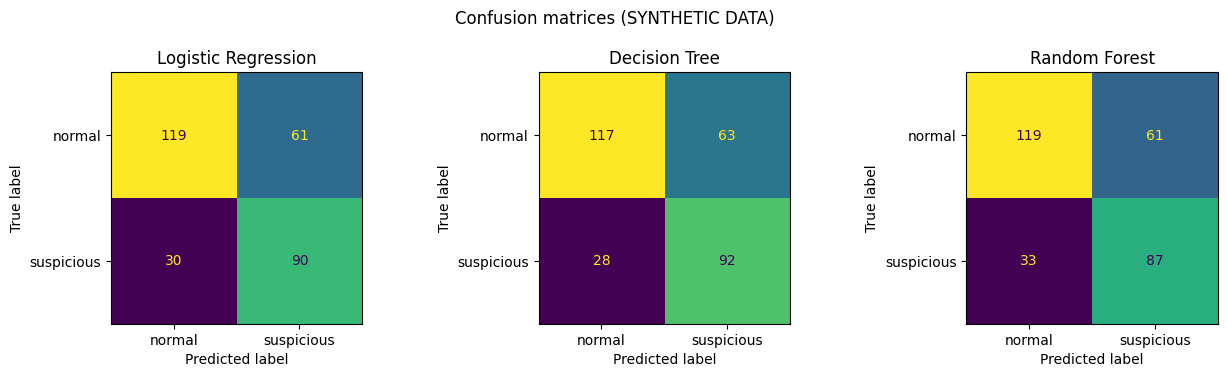

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))
for ax, (name, model) in zip(axes, models.items()):
    cm = confusion_matrix(y_test, model.predict(X_test), labels=[0, 1])
    ConfusionMatrixDisplay(cm, display_labels=["normal", "suspicious"]).plot(ax=ax, colorbar=False)
    ax.set_title(name)
fig.suptitle("Confusion matrices (SYNTHETIC DATA)")
plt.tight_layout()
plt.show()

## 6. Save the demo model

The file name says **synthetic**, so nobody mistakes it for a real model. The backend can load it later to test the connection.

In [8]:
artifact = {"model": models["Logistic Regression"], "feature_order": features, "note": "Trained on SYNTHETIC data only"}
joblib.dump(artifact, "../models/synthetic_demo_model.joblib")
print("Saved ../models/synthetic_demo_model.joblib")

Saved ../models/synthetic_demo_model.joblib


## What to do next
- Replace the synthetic data with real measurements from `data/raw/` once the experiment protocol is approved and data collection works.
- Report only scores that come from real, documented runs.
- Remember: cache misses alone do not prove an attack.